# 04. 문자열 다루기 · `.str` 접근자 ✂️

실무 데이터의 절반은 **숫자가 아니라 '글자'** 입니다. 그런데 사람이 입력한 글자는
앞뒤에 공백이 붙고, 대소문자가 제각각이고, `4,500원`처럼 단위가 섞여 있죠.

판다스는 문자열 컬럼에 **`.str` 접근자**를 붙이면, `for` 문 없이 **모든 행을 한 번에** 정리할 수 있습니다.

> 🔑 핵심 한 줄 : `Series.str.메서드()` → 파이썬 문자열 메서드를 **컬럼 전체에** 적용
>
> 예) `df['이름'].str.strip()`, `df['이메일'].str.lower()`, `df['가격'].str.replace(',', '')`

오늘 데이터는 **카페 주문 로그**입니다. 일부러 지저분하게 만들어 뒀어요. 하나씩 깨끗하게 다듬어 봅시다.

## 0단계 · 데이터 불러오기 (제공)

In [1]:
# [제공] 라이브러리 & 데이터 로드
import pandas as pd

df = pd.read_csv('data/주문로그.csv')
df

,주문번호,주문일시,고객이메일,상품명,가격,주소,수량
0,1,2025-03-13 08:15,Kim.JY@Gmail.com,아이스 아메리카노,"4,500원",서울특별시 강남구,2
1,2,2025-03-13 09:40,lee2025@NAVER.com,카페라떼,"5,000원",서울특별시 마포구,1
2,3,2025-03-13 12:05,PARK_minsu@daum.net,ICE 카페라떼,"5,500원",경기도 성남시,1
3,4,2025-03-13 13:22,choi.aa@gmail.com,아메리카노,"4,500원",서울특별시 강남구,3
4,5,2025-03-13 17:48,jung_h@KAKAO.com,아이스 바닐라라떼,"6,000원",서울특별시 송파구,1
5,6,2025-03-14 08:03,yoon2024@naver.com,ice 아메리카노,"4,500원",경기도 수원시,2
6,7,2025-03-14 10:30,SEO.jy@Gmail.com,카푸치노,"5,000원",서울특별시 마포구,1
7,8,2025-03-14 11:15,han_dev@daum.net,아이스 카페라떼,"5,500원",서울특별시 강남구,2
8,9,2025-03-14 14:50,lim.sk@NAVER.com,바닐라라떼,"6,000원",인천광역시 연수구,1
9,10,2025-03-14 19:12,kang2025@gmail.com,ICE 아메리카노,"4,500원",서울특별시 송파구,2


## 1단계 · 어디가 지저분한지 눈으로 찾기 (제공)
상품명 앞뒤 공백, 이메일 대소문자, 가격의 `,`와 `원`, 주소가 한 칸에 붙어 있는 것 등을 확인하세요.

In [2]:
# [제공] 값들을 살펴보기
print('상품명 예시 :', df['상품명'].unique()[:6])
print('이메일 예시 :', df['고객이메일'].head(3).tolist())
print('가격 예시   :', df['가격'].head(3).tolist())
df.info()

상품명 예시 : <StringArray>
['  아이스 아메리카노', '카페라떼 ', 'ICE 카페라떼', '아메리카노', '아이스 바닐라라떼 ', 'ice 아메리카노']
Length: 6, dtype: str
이메일 예시 : ['  Kim.JY@Gmail.com ', 'lee2025@NAVER.com', 'PARK_minsu@daum.net ']
가격 예시   : ['4,500원', '5,000원', '5,500원']
<class 'pandas.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   주문번호    25 non-null     int64
 1   주문일시    25 non-null     str  
 2   고객이메일   25 non-null     str  
 3   상품명     25 non-null     str  
 4   가격      25 non-null     str  
 5   주소      25 non-null     str  
 6   수량      25 non-null     int64
dtypes: int64(2), str(5)
memory usage: 1.5 KB


## 🎯 미션 1 · 앞뒤 공백 제거 `.str.strip()`
`상품명`과 `고객이메일`의 앞뒤 공백을 없애 원래 컬럼에 다시 저장하세요.

In [3]:
# [미션 1] 공백 제거
#  df['상품명'] 과 df['고객이메일'] 에 .str.strip() 을 적용해 다시 저장

# 👉 여기에 코드를 작성하세요

df['상품명'] = df['상품명'].str.strip()
df['고객이메일'] = df['고객이메일'].str.strip()
#============================================
print('상품명 예시 : ', df['상품명'].unique())
print('이메일 예시 : ', df['고객이메일'].tolist())

상품명 예시 :  <StringArray>
['아이스 아메리카노',      '카페라떼',  'ICE 카페라떼',     '아메리카노', '아이스 바닐라라떼', 'ice 아메리카노',
      '카푸치노',  '아이스 카페라떼',     '바닐라라떼', 'ICE 아메리카노',  'ice 카푸치노', 'ICE 바닐라라떼']
Length: 12, dtype: str
이메일 예시 :  ['Kim.JY@Gmail.com', 'lee2025@NAVER.com', 'PARK_minsu@daum.net', 'choi.aa@gmail.com', 'jung_h@KAKAO.com', 'yoon2024@naver.com', 'SEO.jy@Gmail.com', 'han_dev@daum.net', 'lim.sk@NAVER.com', 'kang2025@gmail.com', 'moon.jh@kakao.com', 'jang@Naver.com', 'shin_2024@daum.net', 'oh.min@GMAIL.com', 'baek.jy@naver.com', 'YUN_hs@Kakao.com', 'jo2025@gmail.com', 'nam.dev@DAUM.net', 'koo_hj@naver.com', 'ha.jy@Gmail.com', 'seong@kakao.com', 'woo_2024@NAVER.com', 'ryu.min@daum.net', 'im.hs@gmail.com', 'noh2025@Kakao.com']


## 🎯 미션 2 · 이메일 소문자로 통일 `.str.lower()`
이메일은 대소문자를 구분하지 않으니 모두 소문자로 맞춥니다.

In [4]:
# [미션 2] 소문자 변환
#  df['고객이메일'] 에 .str.lower() 적용 후 다시 저장

# 👉 여기에 코드를 작성하세요

df['고객이메일'] = df['고객이메일'].str.lower()

## 🎯 미션 3 · 상품명 표기 통일 `.str.replace()`

같은 메뉴인데 `아이스 아메리카노` · `ICE 아메리카노` · `ice 아메리카노` 로 제각각입니다.
영어 `ICE`/`ice` 를 모두 한글 `아이스` 로 바꿔 표기를 통일하세요.

In [5]:
# [미션 3] 표기 통일 (ICE / ice → 아이스)
#  .str.replace('바꿀문자', '새문자') 를 이어서 두 번 적용

# 👉 여기에 코드를 작성하세요

df['상품명'] = df['상품명'].str.upper().str.replace('ICE','아이스')
df['상품명'].unique()

<StringArray>
['아이스 아메리카노',      '카페라떼',  '아이스 카페라떼',     '아메리카노', '아이스 바닐라라떼',      '카푸치노',
     '바닐라라떼',  '아이스 카푸치노']
Length: 8, dtype: str

## 🎯 미션 4 · 특정 단어가 든 행만 골라내기 `.str.contains()`
상품명에 `'아메리카노'` 가 포함된 주문만 필터링해 몇 건인지 확인하세요.

In [6]:
# [미션 4] '아메리카노' 포함 주문만
#  조건: df['상품명'].str.contains('아메리카노')  → df[조건]

# 👉 여기에 코드를 작성하세요

cond_americano = df['상품명'].str.contains('아메리카노')
df.loc[cond_americano]

,주문번호,주문일시,고객이메일,상품명,가격,주소,수량
0,1,2025-03-13 08:15,kim.jy@gmail.com,아이스 아메리카노,"4,500원",서울특별시 강남구,2
3,4,2025-03-13 13:22,choi.aa@gmail.com,아메리카노,"4,500원",서울특별시 강남구,3
5,6,2025-03-14 08:03,yoon2024@naver.com,아이스 아메리카노,"4,500원",경기도 수원시,2
9,10,2025-03-14 19:12,kang2025@gmail.com,아이스 아메리카노,"4,500원",서울특별시 송파구,2
11,12,2025-03-15 10:44,jang@naver.com,아이스 아메리카노,"4,500원",서울특별시 강남구,4
13,14,2025-03-15 15:20,oh.min@gmail.com,아메리카노,"4,500원",경기도 수원시,2
16,17,2025-03-16 11:50,jo2025@gmail.com,아이스 아메리카노,"4,500원",서울특별시 강남구,1
20,21,2025-03-17 08:20,seong@kakao.com,아메리카노,"4,500원",경기도 수원시,1
21,22,2025-03-17 10:11,woo_2024@naver.com,아이스 아메리카노,"4,500원",서울특별시 강남구,2


## 🎯 미션 5 · 이메일에서 도메인 추출 `.str.split()`
`'@'` 를 기준으로 나눈 뒤 뒤쪽(도메인)만 뽑아 `도메인` 컬럼을 만드세요. (`gmail.com`, `naver.com` …)

In [7]:
# [미션 5] 이메일 도메인 추출
#  .str.split('@') 로 나눈 리스트에서 .str[1] 로 뒤쪽만 선택

# 👉 여기에 코드를 작성하세요
domain = df['고객이메일'].str.split('@').str[1]
domain

# import seaborn as sns
# sns.countplot(domain)

0     gmail.com
1     naver.com
2      daum.net
3     gmail.com
4     kakao.com
5     naver.com
6     gmail.com
7      daum.net
8     naver.com
9     gmail.com
10    kakao.com
11    naver.com
12     daum.net
13    gmail.com
14    naver.com
15    kakao.com
16    gmail.com
17     daum.net
18    naver.com
19    gmail.com
20    kakao.com
21    naver.com
22     daum.net
23    gmail.com
24    kakao.com
Name: 고객이메일, dtype: object

## 🎯 미션 6 · 주소를 시도 / 시군구로 분리 `.str.split()`
`'서울특별시 강남구'` 를 공백으로 나눠 `시도`, `시군구` 두 컬럼으로 만드세요.

In [8]:
# [미션 6] 주소 분리
#  방법: .str.split(' ') 후 .str[0](시도) / .str[1](시군구)

# 👉 여기에 코드를 작성하세요
df['시도'] = df['주소'].str.strip().str.split(' ').str[0]
df['시군구'] = df['주소'].str.strip().str.split(' ').str[1]
df


,주문번호,주문일시,고객이메일,상품명,가격,주소,수량,시도,시군구
0,1,2025-03-13 08:15,kim.jy@gmail.com,아이스 아메리카노,"4,500원",서울특별시 강남구,2,서울특별시,강남구
1,2,2025-03-13 09:40,lee2025@naver.com,카페라떼,"5,000원",서울특별시 마포구,1,서울특별시,마포구
2,3,2025-03-13 12:05,park_minsu@daum.net,아이스 카페라떼,"5,500원",경기도 성남시,1,경기도,성남시
3,4,2025-03-13 13:22,choi.aa@gmail.com,아메리카노,"4,500원",서울특별시 강남구,3,서울특별시,강남구
4,5,2025-03-13 17:48,jung_h@kakao.com,아이스 바닐라라떼,"6,000원",서울특별시 송파구,1,서울특별시,송파구
5,6,2025-03-14 08:03,yoon2024@naver.com,아이스 아메리카노,"4,500원",경기도 수원시,2,경기도,수원시
6,7,2025-03-14 10:30,seo.jy@gmail.com,카푸치노,"5,000원",서울특별시 마포구,1,서울특별시,마포구
7,8,2025-03-14 11:15,han_dev@daum.net,아이스 카페라떼,"5,500원",서울특별시 강남구,2,서울특별시,강남구
8,9,2025-03-14 14:50,lim.sk@naver.com,바닐라라떼,"6,000원",인천광역시 연수구,1,인천광역시,연수구
9,10,2025-03-14 19:12,kang2025@gmail.com,아이스 아메리카노,"4,500원",서울특별시 송파구,2,서울특별시,송파구


## 🎯 미션 7 · 가격 텍스트를 숫자로 (실무 핵심!)

`'4,500원'` 은 글자라서 계산이 안 됩니다. `,` 와 `원` 을 지우고 **정수**로 바꿔
`가격_숫자` 컬럼을 만든 뒤, `매출`(가격 × 수량)까지 계산하세요.

In [10]:
# [미션 7] '4,500원' → 4500 (숫자) → 매출 계산
#  1) .str.replace 로 ',' 와 '원' 제거
#  2) .astype(int) 로 정수 변환
#  3) 매출 = 가격_숫자 * 수량

# 👉 여기에 코드를 작성하세요

df['가격_숫자'] = df['가격'].str.replace(',','').str.replace('원','').astype(int)
df['매출'] = df['가격_숫자']*df['수량']
df

,주문번호,주문일시,고객이메일,상품명,가격,주소,수량,시도,시군구,가격_숫자,매출
0,1,2025-03-13 08:15,kim.jy@gmail.com,아이스 아메리카노,"4,500원",서울특별시 강남구,2,서울특별시,강남구,4500,9000
1,2,2025-03-13 09:40,lee2025@naver.com,카페라떼,"5,000원",서울특별시 마포구,1,서울특별시,마포구,5000,5000
2,3,2025-03-13 12:05,park_minsu@daum.net,아이스 카페라떼,"5,500원",경기도 성남시,1,경기도,성남시,5500,5500
3,4,2025-03-13 13:22,choi.aa@gmail.com,아메리카노,"4,500원",서울특별시 강남구,3,서울특별시,강남구,4500,13500
4,5,2025-03-13 17:48,jung_h@kakao.com,아이스 바닐라라떼,"6,000원",서울특별시 송파구,1,서울특별시,송파구,6000,6000
5,6,2025-03-14 08:03,yoon2024@naver.com,아이스 아메리카노,"4,500원",경기도 수원시,2,경기도,수원시,4500,9000
6,7,2025-03-14 10:30,seo.jy@gmail.com,카푸치노,"5,000원",서울특별시 마포구,1,서울특별시,마포구,5000,5000
7,8,2025-03-14 11:15,han_dev@daum.net,아이스 카페라떼,"5,500원",서울특별시 강남구,2,서울특별시,강남구,5500,11000
8,9,2025-03-14 14:50,lim.sk@naver.com,바닐라라떼,"6,000원",인천광역시 연수구,1,인천광역시,연수구,6000,6000
9,10,2025-03-14 19:12,kang2025@gmail.com,아이스 아메리카노,"4,500원",서울특별시 송파구,2,서울특별시,송파구,4500,9000


## 🎯 미션 8 · '아이스 메뉴' 여부 표시 `.str.startswith()`
상품명이 `'아이스'` 로 시작하는지 True/False 로 `아이스여부` 컬럼을 만드세요.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import platform
_os = platform.system()
if _os == 'Windows':
    plt.rc('font', family='Malgun Gothic')
elif _os == 'Darwin':
    plt.rc('font', family='AppleGothic')
else:
    plt.rc('font', family='NanumGothic')
plt.rc('axes', unicode_minus=False)



df['아이스여부'] = df['상품명'].str.startswith('아이스')

In [ ]:
gubun = ['상품명', '시도', '아이스여부']

fig, axes = plt.subplots(1, 3, figsize=(15,5))
for i, g in enumerate(gubun):
    sns.barplot(data=df, x=g, y='매출', estimator=sum, ax=axes[i], errorbar=None)
    if i==0:
        axes[i].tick_params(axis='x', labelrotation=45)

plt.tight_layout()

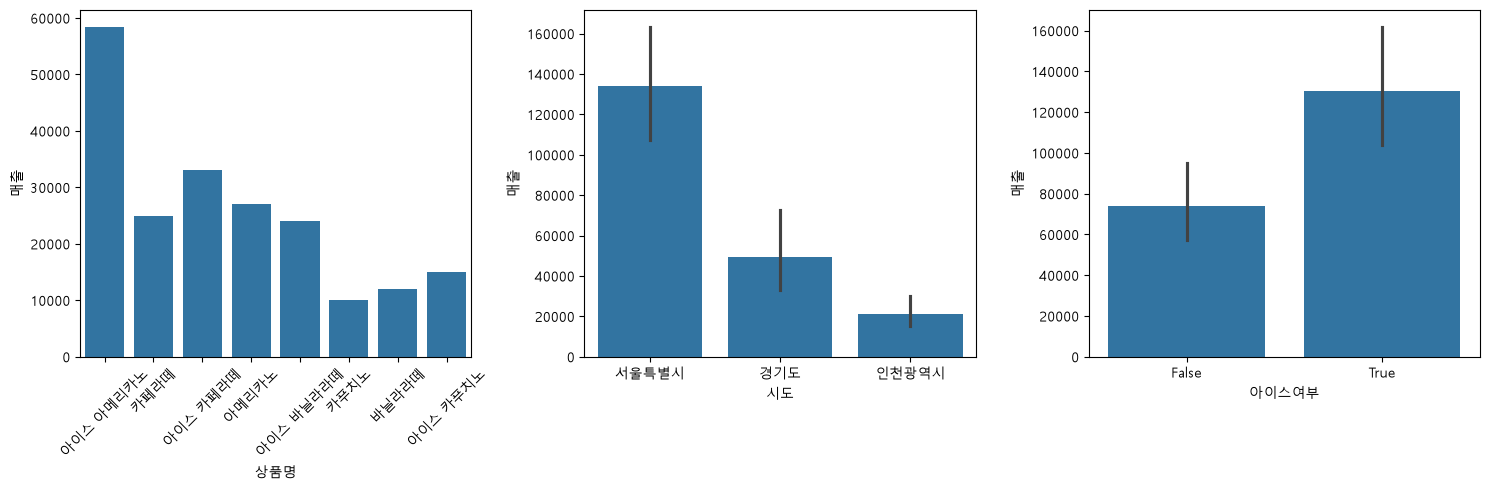

In [ ]:
# [미션 8] 아이스 메뉴 여부
#  df['상품명'].str.startswith('아이스') → True/False

# 👉 여기에 코드를 작성하세요

gubun = ['상품명', '시도', '아이스여부']

fig, axes = plt.subplots(1,3, figsize=(15,5))
sns.barplot(data=df, x='상품명', y='매출', estimator=sum, ax=axes[0], errorbar=None)
sns.barplot(data=df, x='시도', y='매출', estimator=sum, ax=axes[1])
sns.barplot(data=df, x='아이스여부', y='매출', estimator=sum, ax=axes[2])
axes[0].tick_params(axis='x', labelrotation=45)
plt.tight_layout()

## ✅ 정리 · 정제 결과 확인
지저분했던 원본이 계산·분석 가능한 깔끔한 표로 바뀌었습니다.

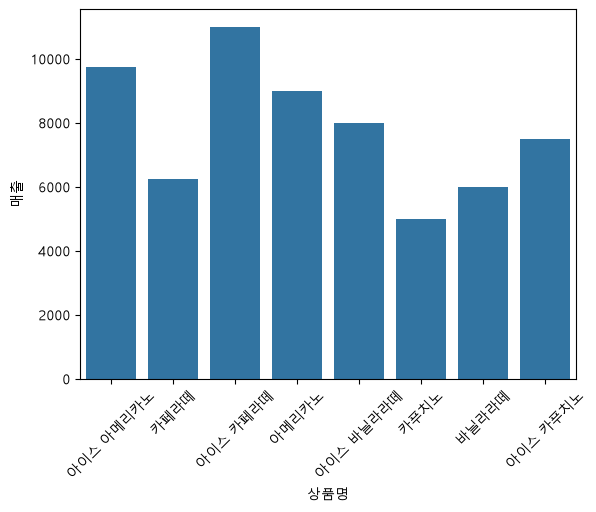

In [12]:
# 최종 결과 확인

# 👉 여기에 코드를 작성하세요
sns.barplot(data = df, x='상품명', y='매출', errorbar=None)
plt.xticks(rotation=45)
pass

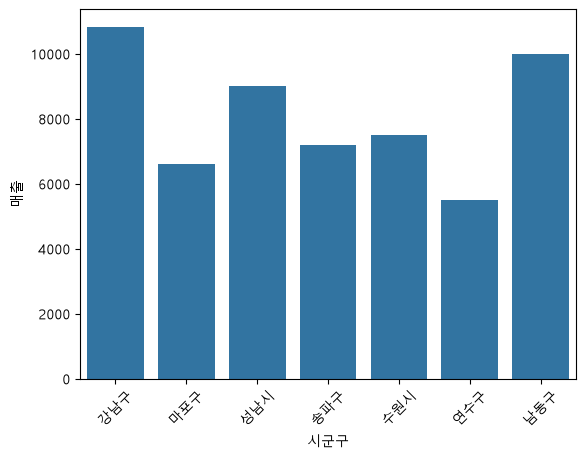

In [14]:
# 시군구별 총 매출액 시각화

sns.barplot(data = df, x='시군구', y='매출', errorbar=None)
plt.xticks(rotation=45)
pass

## 🎉 정제하니 이런 게 됩니다! (정제 전엔 불가능했던 것들)

정제는 그 자체가 목적이 아니라 **분석을 위한 준비**입니다. 방금 만든 컬럼들로,
정제 전에는 **불가능했던** 요약을 한 줄로 확인해 보세요. (본격 요약은 내일 `groupby`에서!)

In [ ]:
# [보너스] 정제 덕분에 가능해진 것들
#  1) 총 매출  → df['매출'].sum()        (가격이 '4,500원' 글자였을 땐 계산 불가!)
#  2) 베스트 메뉴 → df['상품명'].value_counts()  (표기 통일 안 했으면 ICE/ice/아이스 따로 세어짐)
#  3) 도메인 분포 → df['도메인'].value_counts()

# 👉 여기에 코드를 작성하세요



---
### 💡 오늘 배운 `.str` 메서드 한눈에

| 메서드 | 하는 일 | 예시 |
|--------|---------|------|
| `.str.strip()` | 앞뒤 공백 제거 | `'  라떼 '` → `'라떼'` |
| `.str.lower()` / `.upper()` | 소/대문자 변환 | `'A@B.com'` → `'a@b.com'` |
| `.str.replace(a, b)` | 문자 바꾸기 | `'4,500'` → `'4500'` |
| `.str.contains(w)` | 단어 포함 여부(필터) | `'아메리카노' 포함?` |
| `.str.split(구분자).str[i]` | 나누고 i번째 선택 | `'a@b.com'` → `'b.com'` |
| `.str.startswith(w)` | 특정 단어로 시작? | `'아이스…'` → `True` |
| `.astype(int)` | 문자 → 숫자 | `'4500'` → `4500` |

> ✨ 공통점: **모두 `for` 문 없이 컬럼 전체에 한 번에 적용**됩니다. 이게 `.str` 접근자의 힘이에요.
